In [27]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import RidgeClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RandomizedSearchCV

In [28]:
df         = pd.read_excel('prediction_NHANES_train.xlsx')
dff         = pd.read_excel('prediction_NHANES_test.xlsx')
dfx         =pd.read_excel('prediction_NHANES.xlsx')
df2        = pd.read_excel('prediction_cohort.xlsx')

In [29]:
y_train = df['GDM']#Series,最终分类
X_train = df[['Age.Class', 'BMI.Class', 'Pregnancy.times','Parturition.times','UA','ALT','AST','GGT','PLT','Ca','NPAR']]
y_test=dff['GDM']
X_test=dff[['Age.Class', 'BMI.Class', 'Pregnancy.times','Parturition.times','UA','ALT','AST','GGT','PLT','Ca','NPAR']]


Y2=df2['GDM']
X2=df2[['Age.Class', 'BMI.Class', 'Pregnancy.times','Parturition.times','UA','ALT','AST','GGT','PLT','Ca','NPAR']]

In [30]:
#X标准化处理，它将数据转换为均值为 0，标准差为 1 的标准正态分布
def Sd(XX,YY):

    X_np   = np.array(XX)
    sc     = StandardScaler()
    X_norm = sc.fit_transform(X_np)
    XX      = X_norm

    YYY=YY.values
    return XX,YYY
X2,Y2=Sd(X2,Y2)
X_train,y_train=Sd(X_train,y_train)
X_test,y_test=Sd(X_test,y_test)

## Model training

In [31]:
#未进行
from sklearn.datasets import make_classification
from imblearn.over_sampling import SMOTE
from collections import Counter


# 初始化SMOTE
smote = SMOTE(random_state=42)

# 应用SMOTE进行过采样
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

# 查看平衡后的数据集的类别分布
print("平衡后数据集类别分布:", Counter(y_resampled))

# 创建平衡后的DataFrame
X_train=X_resampled
y_train=y_resampled

平衡后数据集类别分布: Counter({0: 425, 1: 425})


In [18]:
# Model creation
List_of_models = [LogisticRegression(random_state=42), 
                  KNeighborsClassifier(), 
                  GaussianNB(), 
                  DecisionTreeClassifier(random_state=42),
                  SVC(probability=True), 
                  RandomForestClassifier(random_state=42)]
List_of_models_for_graph = ["LogisticRegression", "KNeighborsClassifier", "GaussianNB", "DecisionTreeClassifier","SVM", "RandomForestClassifier"]



In [19]:
def getcan():
    #index行，columns列
    df_results = pad.DataFrame(index = ["train accuracy", "test accuracy","ex accuracy","train auc","test auc","ex auc"])

    for i in range(len(List_of_models)):
        model_class = List_of_models[i] 
        model_class.fit(X_train, y_train)

        y_scores = model_class.predict_proba(X_train)[:, 1]  # 获取正类的预测概率
        auc1 = roc_auc_score(y_train, y_scores)
        y_scores = model_class.predict_proba(X_test)[:, 1]  # 获取正类的预测概率
        auc2 = roc_auc_score(y_test, y_scores)
        y_scores = model_class.predict_proba(X2)[:, 1]  # 获取正类的预测概率
        auc3 = roc_auc_score(Y2, y_scores)

        results_classification = np.array([model_class.score(X_train,y_train), model_class.score(X_test,y_test),model_class.score(X2,Y2),auc1,auc2,auc3])
        df_results[List_of_models_for_graph[i]] = results_classification
    df_graph = df_results.transpose()#行列交换，转置
    return df_graph

In [20]:
getcan()

,train accuracy,test accuracy,ex accuracy,train auc,test auc,ex auc
LogisticRegression,0.660000,0.635659,0.581477,0.705329,0.681923,0.592113
KNeighborsClassifier,0.863529,0.620155,0.601407,0.983956,0.581154,0.553401
GaussianNB,0.648235,0.627907,0.635404,0.708108,0.620385,0.576855
DecisionTreeClassifier,1.000000,0.387597,0.432591,1.000000,0.559423,0.516583
SVM,0.868235,0.674419,0.621336,0.948866,0.653462,0.542005
RandomForestClassifier,1.000000,0.565891,0.582649,1.000000,0.593846,0.580562


网格搜索，自动调参

In [21]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
logistic_parameters = {
    'solver': ['liblinear', 'lbfgs', 'newton-cg', 'sag', 'saga'],  # 不同的求解器
    'penalty': ['l1', 'l2', 'elasticnet'],  # 正则化类型
    'C': [0.01, 0.1, 1, 10, 100],  # 正则化强度的倒数
    'max_iter': [1,2,3,5,10,25,50,100],  # 最大迭代次数
    'fit_intercept': [True, False]  # 是否拟合截距
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
logistic_GridSearchCV = GridSearchCV(estimator = LogisticRegression(random_state=42), param_grid = logistic_parameters, n_jobs=-1,cv=cv)
#GridSearchCV分类问题默认用accuracy作为评判指标
logistic_GridSearchCV.fit(X_train, y_train)


List_of_models[0]=logistic_GridSearchCV.best_estimator_
print(logistic_GridSearchCV.best_params_)
getcan()


c:\Users\12750\anaconda3\envs\dby\Lib\site-packages\sklearn\model_selection\_validation.py:540: FitFailedWarning: 
6400 fits failed out of a total of 12000.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
800 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\12750\anaconda3\envs\dby\Lib\site-packages\sklearn\model_selection\_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\12750\anaconda3\envs\dby\Lib\site-packages\sklearn\base.py", line 1473, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\12750\anaconda3\envs\dby\Lib\site-packages\sklearn\linear_model\_logi

{'C': 0.1, 'fit_intercept': False, 'max_iter': 2, 'penalty': 'l1', 'solver': 'liblinear'}


,train accuracy,test accuracy,ex accuracy,train auc,test auc,ex auc
LogisticRegression,0.665882,0.565891,0.548652,0.690552,0.678846,0.586689
KNeighborsClassifier,0.863529,0.620155,0.601407,0.983956,0.581154,0.553401
GaussianNB,0.648235,0.627907,0.635404,0.708108,0.620385,0.576855
DecisionTreeClassifier,1.000000,0.387597,0.432591,1.000000,0.559423,0.516583
SVM,0.868235,0.674419,0.621336,0.948872,0.653462,0.542120
RandomForestClassifier,1.000000,0.565891,0.582649,1.000000,0.593846,0.580562


In [45]:

knn = KNeighborsClassifier()
# 定义超参数网格
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11,13],  # K 值
    'weights': ['uniform', 'distance'],  # 权重类型
    'metric': ['euclidean', 'manhattan']  # 距离度量
}

# 设置网格搜索
grid_search = GridSearchCV(estimator=knn, param_grid=param_grid, 
                           cv=cv, n_jobs=-1)

# 进行网格搜索
grid_search.fit(X_train, y_train)
List_of_models[1]=grid_search.best_estimator_
print(grid_search.best_params_)
getcan()


{'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}


/opt/conda/envs/npar/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,train accuracy,test accuracy,ex accuracy,train auc,test auc,ex auc
LogisticRegression,0.826590,0.798450,0.716295,0.696921,0.723462,0.585539
KNeighborsClassifier,0.834297,0.806202,0.723329,0.797647,0.555577,0.558795
GaussianNB,0.797688,0.775194,0.709261,0.688160,0.641538,0.582516
DecisionTreeClassifier,1.000000,0.689922,0.685815,1.000000,0.519038,0.528635
SVM,0.838150,0.806202,0.717468,0.922954,0.624231,0.544109
RandomForestClassifier,1.000000,0.790698,0.718640,1.000000,0.631154,0.586533


In [46]:
gnb = GaussianNB()

# 定义超参数网格
param_grid = {
    'var_smoothing': np.logspace(0, -9, num=100)  # 平滑参数
}

# 设置网格搜索
grid_search = GridSearchCV(estimator=gnb, param_grid=param_grid, 
                           cv=cv, n_jobs=-1)

# 进行网格搜索
grid_search.fit(X_train, y_train)
List_of_models[2]=grid_search.best_estimator_
print(grid_search.best_params_)
getcan()

{'var_smoothing': np.float64(1.0)}


/opt/conda/envs/npar/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,train accuracy,test accuracy,ex accuracy,train auc,test auc,ex auc
LogisticRegression,0.826590,0.798450,0.716295,0.696921,0.723462,0.585539
KNeighborsClassifier,0.834297,0.806202,0.723329,0.797647,0.555577,0.558795
GaussianNB,0.818882,0.790698,0.719812,0.688260,0.659231,0.590091
DecisionTreeClassifier,1.000000,0.689922,0.685815,1.000000,0.519038,0.528635
SVM,0.838150,0.806202,0.717468,0.922954,0.624231,0.544109
RandomForestClassifier,1.000000,0.790698,0.718640,1.000000,0.631154,0.586533


In [47]:
# Model DecisionTree
DecisionTreeClassifier_parameters = {#'max_features' : ['auto', 'sqrt', 'log2'],
                                     'max_depth': [None, 1,2, 10, 15,18,20],
                                     'min_samples_leaf': [1, 2, 5, 10, 20, 50, 100],
                                     "min_samples_split": [1,2, 6, 20],
                                     'criterion': ["gini", "entropy"],
                                     'splitter' : ['best', 'random'],}

DecisionTreeClassifier_GridSearchCV = GridSearchCV(estimator = DecisionTreeClassifier(random_state=42), param_grid = DecisionTreeClassifier_parameters,cv=cv, n_jobs=-1, verbose = 0)
DecisionTreeClassifier_GridSearchCV.fit(X_train, y_train)
# DecisionTreeClassifier_GridSearchCV.best_params_
List_of_models[3]=DecisionTreeClassifier_GridSearchCV.best_estimator_
print(DecisionTreeClassifier_GridSearchCV.best_params_)
getcan()

/opt/conda/envs/npar/lib/python3.11/site-packages/sklearn/model_selection/_validation.py:540: FitFailedWarning: 
1960 fits failed out of a total of 7840.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1960 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/conda/envs/npar/lib/python3.11/site-packages/sklearn/model_selection/_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/opt/conda/envs/npar/lib/python3.11/site-packages/sklearn/base.py", line 1466, in wrapper
    estimator._validate_params()
  File "/opt/conda/envs/npar/lib/python3.11/site-packages/sklearn/base.py", line 666, in _validate_params
    validate_parameter_constraints(
  File "/opt/cond

{'criterion': 'entropy', 'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'best'}


,train accuracy,test accuracy,ex accuracy,train auc,test auc,ex auc
LogisticRegression,0.826590,0.798450,0.716295,0.696921,0.723462,0.585539
KNeighborsClassifier,0.834297,0.806202,0.723329,0.797647,0.555577,0.558795
GaussianNB,0.818882,0.790698,0.719812,0.688260,0.659231,0.590091
DecisionTreeClassifier,0.830443,0.790698,0.713951,0.682916,0.590769,0.522193
SVM,0.838150,0.806202,0.717468,0.922954,0.624231,0.544109
RandomForestClassifier,1.000000,0.790698,0.718640,1.000000,0.631154,0.586533


In [48]:
# Modèle RandomForestClassifier
RandomForestClassifier_parameters = {'criterion' : ['gini', 'entropy'],
                                     'n_estimators' : [1,10,20,30, 100, 200, 400], 
                                     'min_samples_split' : [7,9,10,20,30], 
                                     'min_samples_leaf' : [1,2,5,7,9,10], 
                                     'max_features' : ['sqrt', 'log2'],
                                     }


RandomForestClassifier_GridSearchCV = GridSearchCV(estimator = RandomForestClassifier(random_state=42), param_grid = RandomForestClassifier_parameters, cv=cv, n_jobs=-1, verbose=0
        )
RandomForestClassifier_GridSearchCV.fit(X_train, y_train)
# RandomForestClassifier_GridSearchCV.best_params_
List_of_models[5]=RandomForestClassifier_GridSearchCV.best_estimator_
print(RandomForestClassifier_GridSearchCV.best_params_)
getcan()


/opt/conda/envs/npar/lib/python3.11/site-packages/numpy/ma/core.py:2881: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


{'criterion': 'gini', 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 7, 'n_estimators': 100}


/opt/conda/envs/npar/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,train accuracy,test accuracy,ex accuracy,train auc,test auc,ex auc
LogisticRegression,0.826590,0.798450,0.716295,0.696921,0.723462,0.585539
KNeighborsClassifier,0.834297,0.806202,0.723329,0.797647,0.555577,0.558795
GaussianNB,0.818882,0.790698,0.719812,0.688260,0.659231,0.590091
DecisionTreeClassifier,0.830443,0.790698,0.713951,0.682916,0.590769,0.522193
SVM,0.838150,0.806202,0.717468,0.922954,0.624231,0.544109
RandomForestClassifier,0.928709,0.798450,0.719812,0.998423,0.689231,0.586391


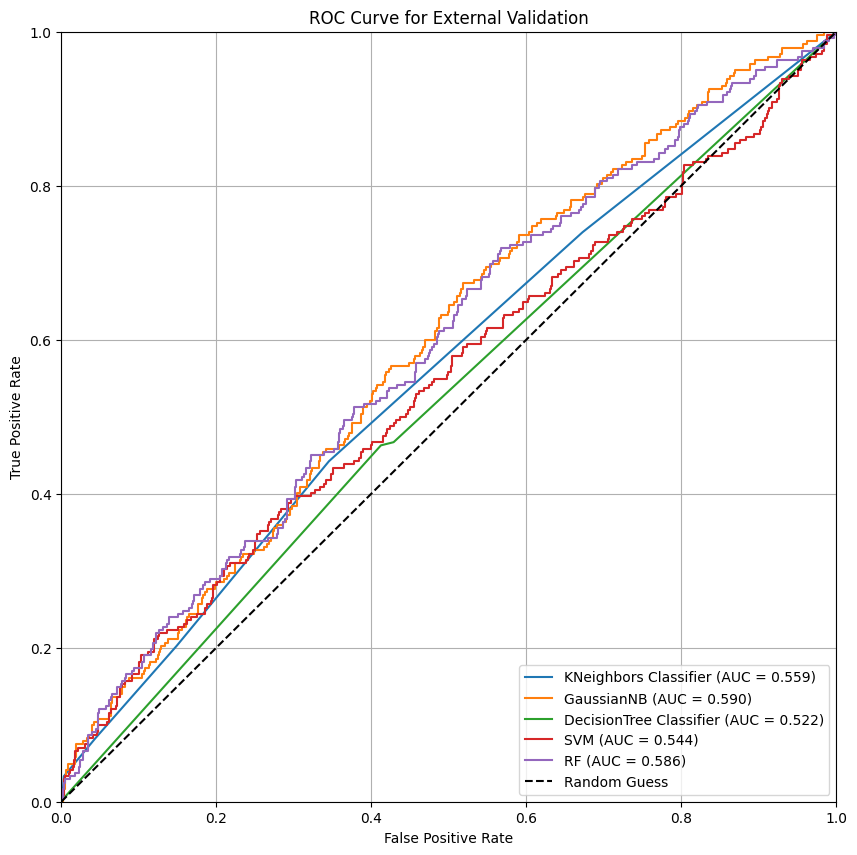

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.metrics import roc_curve, auc


# 定义模型
models = {
    "KNeighbors Classifier": List_of_models[1],
    "GaussianNB": List_of_models[2],
    "DecisionTree Classifier": List_of_models[3],
    "SVM": List_of_models[4],
    "RF": List_of_models[5],
}

# 绘制ROC曲线
plt.figure(figsize=(10, 10))

for name, model in models.items():
    y_scores = model.predict_proba(X2)[:, 1]  # 获取正类的概率
    fpr, tpr, _ = roc_curve(Y2, y_scores)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

# 绘制随机猜测线
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

# 设置图形属性
plt.title('ROC Curve for External Validation')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.grid()

# 显示图形
plt.show()

